# Research 01 — Class-prior correction

**Hypothesis:** the equal CatBoost/LightGBM blend favors frequent class 0, and a mild inverse-prior correction may lift macro F1. This tests one predeclared correction (divide each class probability by the square root of its training prior); there is no parameter sweep. Validation uses the saved three-fold OOF probabilities. Test data is not loaded.

This is a negative-result screen: if it does not improve OOF macro F1, keep the uncorrected blend.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data" / "train.csv").is_file()
)
if not (ROOT / "predictions/segment-oof.csv").exists():
    ROOT = ROOT.parent
oof = pd.read_csv(ROOT / "predictions/segment-oof.csv")
y = oof["segment"].to_numpy(dtype=int)
p = oof[[f"prob_{i}" for i in range(4)]].to_numpy()
prior = np.bincount(y, minlength=4) / len(y)
assert np.isfinite(p).all() and np.allclose(p.sum(axis=1), 1, atol=1e-5)
print(f"OOF rows={len(y):,}; class priors={prior.round(4)}")

OOF rows=104,000; class priors=[0.3936 0.2503 0.2021 0.154 ]


## Predeclared rule

Use `adjusted_probability[c] = probability[c] / sqrt(prior[c])`. This modestly corrects for the training prevalence without fitting a threshold or searching parameters. It is evaluated against argmax on the same stored OOF bank and on a stratified half-sample screen.

In [2]:
adjusted = p / np.sqrt(prior)[None, :]


def score_row(name, truth, probabilities):
    pred = probabilities.argmax(axis=1)
    return {
        "candidate": name,
        "macro_f1": f1_score(truth, pred, average="macro"),
        "weighted_f1": f1_score(truth, pred, average="weighted"),
    }


results = pd.DataFrame(
    [score_row("argmax baseline", y, p), score_row("sqrt-prior correction", y, adjusted)]
)
display(results)

cal_idx, eval_idx = train_test_split(np.arange(len(y)), test_size=0.5, random_state=137, stratify=y)
cal_prior = np.bincount(y[cal_idx], minlength=4) / len(cal_idx)
heldout = pd.DataFrame(
    [
        score_row("argmax baseline", y[eval_idx], p[eval_idx]),
        score_row("sqrt-prior correction", y[eval_idx], p[eval_idx] / np.sqrt(cal_prior)[None, :]),
    ]
)
print("Half-sample OOF screen (prior estimated on the other half):")
display(heldout)
print(classification_report(y, adjusted.argmax(axis=1), digits=4, zero_division=0))
results.to_csv(ROOT / "assets/segment-prior-correction-results.csv", index=False)

,candidate,macro_f1,weighted_f1
0,argmax baseline,0.750895,0.764683
1,sqrt-prior correction,0.750245,0.763301


Half-sample OOF screen (prior estimated on the other half):


,candidate,macro_f1,weighted_f1
0,argmax baseline,0.75079,0.763893
1,sqrt-prior correction,0.74921,0.762056


              precision    recall  f1-score   support

           0     0.8132    0.8184    0.8158     40934
           1     0.7361    0.7495    0.7427     26034
           2     0.7152    0.7054    0.7103     21014
           3     0.7428    0.7219    0.7322     16018

    accuracy                         0.7635    104000
   macro avg     0.7518    0.7488    0.7502    104000
weighted avg     0.7632    0.7635    0.7633    104000



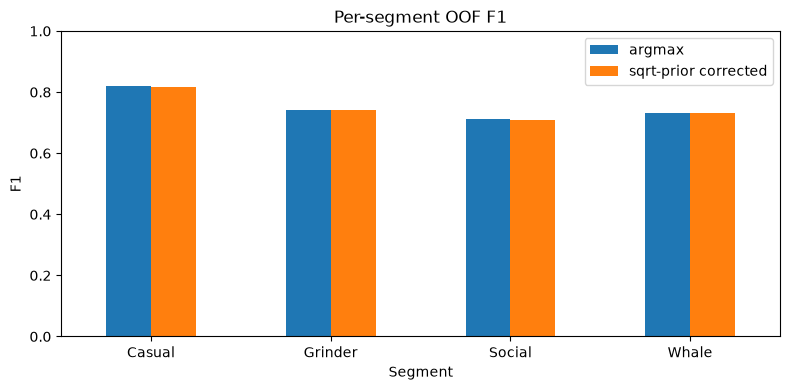

In [3]:
class_f1 = pd.DataFrame(
    {
        name: [
            f1_score(y, probs.argmax(axis=1), labels=range(4), average=None)[i] for i in range(4)
        ]
        for name, probs in [("argmax", p), ("sqrt-prior corrected", adjusted)]
    },
    index=["Casual", "Grinder", "Social", "Whale"],
)
ax = class_f1.plot.bar(figsize=(8, 4), rot=0)
ax.set(title="Per-segment OOF F1", xlabel="Segment", ylabel="F1", ylim=(0, 1))
plt.tight_layout()
plt.savefig(ROOT / "assets/segment-prior-correction-f1.png", dpi=300, bbox_inches="tight")
plt.show()

## Decision

The fixed correction slightly underperformed the unadjusted blend on the complete OOF set and on the half-sample screen. Do not use it for test predictions. The wider pattern is a small recall/precision tradeoff, not a clear global gain. Next research should target a stronger diverse estimator or improve segment distinctions directly rather than shift all class priors.